# Best Subset Selection (BSS) from scratch
**Dataset:** Yacht Hydrodynamics (308 obs, 6 predictors) · **Target:** residuary resistance per unit weight of displacement

Algorithm (from the slides):
1. $M_0$ = null model → predicts the sample mean $\beta_0 = \frac{1}{N}\sum y_i$
2. For $k = 1,\dots,p$: (a) fit all $\binom{p}{k}$ models with exactly $k$ predictors; (b) pick the one with smallest RSS (largest $R^2$) → $M_k$
3. Choose one model among $M_0,\dots,M_p$ using CV prediction error, $C_p$ (AIC), BIC, or adjusted $R^2$

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from itertools import combinations
from math import comb, log

df = pd.read_csv('YachtHydrodynamics.csv')
df.columns = ['LCB', 'Cp_prismatic', 'L_D_ratio', 'B_T_ratio', 'L_B_ratio', 'Froude', 'Resistance']
print(df.shape); df.head()

(308, 7)


,LCB,Cp_prismatic,L_D_ratio,B_T_ratio,L_B_ratio,Froude,Resistance
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


In [2]:
X = df.drop(columns='Resistance'); y = df['Resistance'].values
features = list(X.columns); p = len(features); N = len(y)
print(f'p = {p} predictors -> {2**p} total subsets, N = {N}')
df.describe().T

p = 6 predictors -> 64 total subsets, N = 308


,count,mean,std,min,25%,50%,75%,max
LCB,308.0,-2.381818,1.513219,-5.000,-2.4000,-2.3000,-2.300,0.00
Cp_prismatic,308.0,0.564136,0.023290,0.530,0.5460,0.5650,0.574,0.60
L_D_ratio,308.0,4.788636,0.253057,4.340,4.7700,4.7800,5.100,5.14
B_T_ratio,308.0,3.936818,0.548193,2.810,3.7500,3.9550,4.170,5.35
L_B_ratio,308.0,3.206818,0.247998,2.730,3.1500,3.1500,3.510,3.64
Froude,308.0,0.287500,0.100942,0.125,0.2000,0.2875,0.375,0.45
Resistance,308.0,10.495357,15.160490,0.010,0.7775,3.0650,12.815,62.42


## Helpers: OLS fit & RSS for a subset

In [3]:
def fit_ols(Xmat, y):
    """OLS with intercept via least squares. Returns coefficients (intercept first) and RSS."""
    A = np.column_stack([np.ones(len(y)), Xmat]) if Xmat.shape[1] else np.ones((len(y), 1))
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    resid = y - A @ beta
    return beta, float(resid @ resid)

def predict(beta, Xmat):
    A = np.column_stack([np.ones(len(Xmat)), Xmat]) if Xmat.shape[1] else np.ones((len(Xmat), 1))
    return A @ beta

## Step 1–2: Best subset for each size $k$

In [4]:
def best_subset(Xarr, y):
    """Returns dict k -> (best column-index tuple, RSS, beta). k=0 is the null model."""
    p = Xarr.shape[1]
    beta0, rss0 = fit_ols(Xarr[:, []], y)            # M0: just the mean
    best = {0: ((), rss0, beta0)}
    for k in range(1, p + 1):
        cand = None
        for S in combinations(range(p), k):            # all C(p,k) models
            beta, rss = fit_ols(Xarr[:, S], y)
            if cand is None or rss < cand[1]:
                cand = (S, rss, beta)
        best[k] = cand                                 # M_k
    return best

Xarr = X.values
best = best_subset(Xarr, y)
assert np.isclose(best[0][2][0], y.mean())            # M0 predicts the sample mean

TSS = float(((y - y.mean())**2).sum())
rows = []
for k, (S, rss, _) in best.items():
    rows.append({'k': k, 'features': [features[i] for i in S], 'models_fit': comb(p, k),
                 'RSS': rss, 'R2': 1 - rss/TSS})
summary = pd.DataFrame(rows); summary

,k,features,models_fit,RSS,R2
0,0,[],1,70561.021261,2.220446e-16
1,1,[Froude],6,24255.392578,6.562494e-01
2,2,"[Cp_prismatic, Froude]",15,24197.801051,6.570656e-01
3,3,"[LCB, Cp_prismatic, Froude]",20,24172.165028,6.574289e-01
4,4,"[LCB, Cp_prismatic, L_D_ratio, Froude]",15,24170.898564,6.574469e-01
5,5,"[LCB, L_D_ratio, B_T_ratio, L_B_ratio, Froude]",6,24164.342098,6.575398e-01
6,6,"[LCB, Cp_prismatic, L_D_ratio, B_T_ratio, L_B_...",1,24162.645713,6.575638e-01


## Step 3: Pick a single best model among $M_0,\dots,M_p$
RSS/$R^2$ always improve with $k$, so we use criteria that penalise model size ($d$ = number of predictors, $\hat\sigma^2$ estimated from the full model $M_p$):

- $C_p = \frac{1}{N}(RSS + 2d\hat\sigma^2)$ (equivalent to AIC for Gaussian errors)
- $BIC = \frac{1}{N}(RSS + \log(N)\, d\,\hat\sigma^2)$
- Adjusted $R^2 = 1 - \frac{RSS/(N-d-1)}{TSS/(N-1)}$ (maximise)
- 10-fold cross-validated MSE (BSS is re-run inside every training fold, so the selection isn't leaked into the validation fold)

In [5]:
sigma2 = best[p][1] / (N - p - 1)
crit = summary[['k']].copy()
crit['Cp']     = [(best[k][1] + 2*k*sigma2) / N for k in range(p+1)]
crit['BIC']    = [(best[k][1] + log(N)*k*sigma2) / N for k in range(p+1)]
crit['AdjR2']  = [1 - (best[k][1]/(N-k-1)) / (TSS/(N-1)) for k in range(p+1)]

def cv_mse(Xarr, y, n_splits=10, seed=0):
    rng = np.random.default_rng(seed)
    folds = np.array_split(rng.permutation(len(y)), n_splits)
    errs = np.zeros((n_splits, Xarr.shape[1] + 1))
    for f, val in enumerate(folds):
        tr = np.setdiff1d(np.arange(len(y)), val)
        b = best_subset(Xarr[tr], y[tr])              # BSS on training fold only
        for k, (S, _, beta) in b.items():
            pred = predict(beta, Xarr[val][:, S])
            errs[f, k] = np.mean((y[val] - pred)**2)
    return errs.mean(axis=0), errs.std(axis=0, ddof=1) / np.sqrt(n_splits)

crit['CV_MSE'], cv_se = cv_mse(Xarr, y)
crit

,k,Cp,BIC,AdjR2,CV_MSE
0,0,229.094225,229.094225,1.110223e-16,230.753984
1,1,79.272538,80.244720,6.551260e-01,79.939533
2,2,79.606816,81.551181,6.548169e-01,81.328145
3,3,80.044846,82.961393,6.540483e-01,81.951800
4,4,80.561997,84.450726,6.529247e-01,82.690058
5,5,81.061973,85.922885,6.518699e-01,82.995434
6,6,81.577729,87.410823,6.507379e-01,82.981345


In [6]:
chosen = {
    'Cp (AIC)': int(crit['Cp'].idxmin()),
    'BIC':      int(crit['BIC'].idxmin()),
    'Adj R2':   int(crit['AdjR2'].idxmax()),
    'CV MSE':   int(crit['CV_MSE'].idxmin()),
}
for name, k in chosen.items():
    print(f'{name:9s} -> k = {k}: {[features[i] for i in best[k][0]]}')

Cp (AIC)  -> k = 1: ['Froude']
BIC       -> k = 1: ['Froude']
Adj R2    -> k = 1: ['Froude']
CV MSE    -> k = 1: ['Froude']


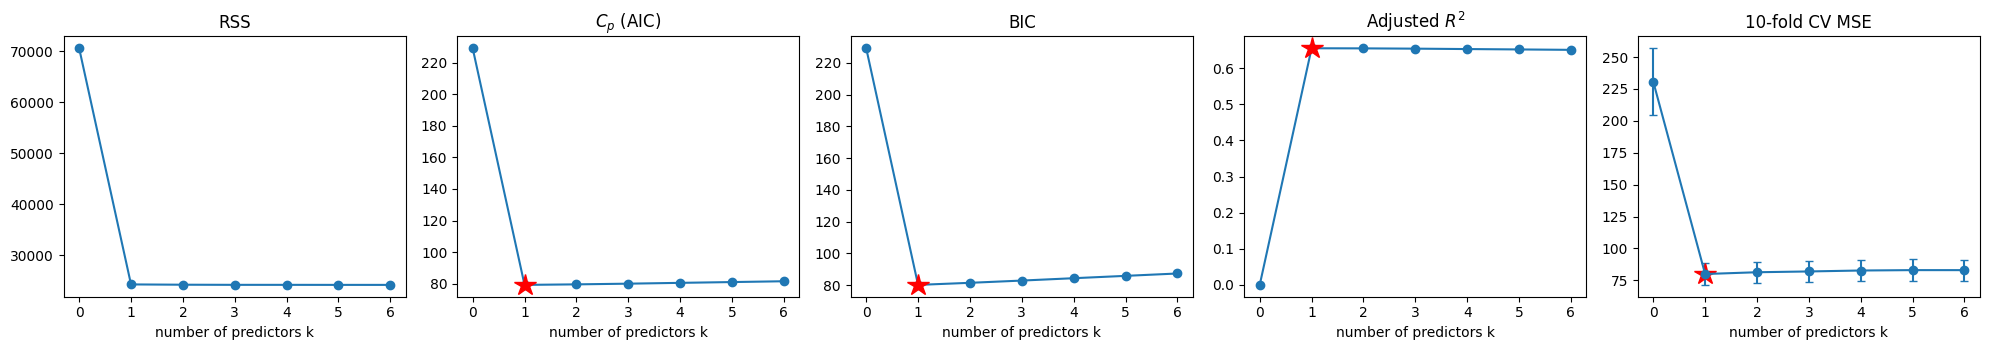

In [7]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
ax[0].plot(crit.k, summary.RSS, 'o-'); ax[0].set_title('RSS')
ax[1].plot(crit.k, crit.Cp, 'o-');     ax[1].set_title('$C_p$ (AIC)')
ax[2].plot(crit.k, crit.BIC, 'o-');    ax[2].set_title('BIC')
ax[3].plot(crit.k, crit.AdjR2, 'o-');  ax[3].set_title('Adjusted $R^2$')
ax[4].errorbar(crit.k, crit.CV_MSE, yerr=cv_se, fmt='o-', capsize=3); ax[4].set_title('10-fold CV MSE')
for a, col, fn in [(ax[1],'Cp',np.argmin),(ax[2],'BIC',np.argmin),(ax[3],'AdjR2',np.argmax),(ax[4],'CV_MSE',np.argmin)]:
    k = fn(crit[col].values); a.plot(k, crit[col][k], 'r*', ms=16)
for a in ax: a.set_xlabel('number of predictors k')
plt.tight_layout(); plt.show()

## Final model (refit on all data with the BIC-selected subset)

In [8]:
k_final = chosen['BIC']
S, rss, beta = best[k_final]
coef = pd.Series(beta, index=['intercept'] + [features[i] for i in S])
print(f'Selected k = {k_final},  R2 = {1 - rss/TSS:.4f},  RSE = {np.sqrt(rss/(N-k_final-1)):.4f}')
coef

Selected k = 1,  R2 = 0.6562,  RSE = 8.9031


intercept    -24.484070
Froude       121.667572
dtype: float64

## Sanity check against scikit-learn (full model)

In [9]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression().fit(Xarr, y)
assert np.allclose(np.r_[lr.intercept_, lr.coef_], best[p][2])
print('Full-model coefficients match sklearn.')

Full-model coefficients match sklearn.


## Notes
- Number of models fitted: $\sum_k \binom{p}{k} = 2^p = 64$ here, trivial. At $p>40$ it becomes infeasible (see slide), where forward/backward stepwise or Lasso are used instead.
- The $C_p$ / BIC / adj-$R^2$ scores use $\hat\sigma^2$ from the full model; CV needs no such estimate.
- Predictors are on different scales, but OLS fits are scale-invariant, so no standardisation is needed for BSS (it would matter for ridge/lasso).